# Bore Oil Production Forecasting

Compare ARIMA, XGBoost, and LSTM forecasts for well `15/9-F-12`.

**Target:** `BORE_OIL_VOL`  
**Input:** Volve production workbook  
**Evaluation:** chronological train, validation, and test periods

## Notebook Guide

Run cells top to bottom. Set the workbook path in the data-loading section.

## Forecasting Objective

Forecast daily bore oil volume from historical values.

## Setup and Data

### Imports and Input Path

Set the Volve workbook path and load analysis libraries.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import seaborn as sns
import optuna 


from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler


from sklearn.model_selection import (
    train_test_split,
    
    cross_val_score,
)


from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)


from xgboost import XGBRegressor
from keras.models import Sequential
from keras.layers import LSTM
from keras.layers import Dense


import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf




d:\GitHub\.ML_Environment\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Load and Select the Production Series

Select well `15/9-F-12` and split its records chronologically (85% train, 15% test).

In [2]:
workbook_path = Path("data/Volve production data.xlsx")

In [3]:
workbook_sheets = pd.read_excel(workbook_path, sheet_name=None)
daily_production_data = workbook_sheets["Daily Production Data"]
monthly_production_data = workbook_sheets["Monthly Production Data"]


In [4]:
production_only_well_names = (                                    
    daily_production_data.groupby("NPD_WELL_BORE_NAME")["FLOW_KIND"]
    .agg(set)
    .loc[lambda x: x == {"production"}]
)

production_only_well_names

NPD_WELL_BORE_NAME
15/9-F-1 C     {production}
15/9-F-11      {production}
15/9-F-12      {production}
15/9-F-14      {production}
15/9-F-15 D    {production}
Name: FLOW_KIND, dtype: object

In [5]:
production_records = daily_production_data[
    daily_production_data["NPD_WELL_BORE_NAME"].isin(production_only_well_names.index)
]
target_well_data = production_records[
    production_records["NPD_WELL_BORE_NAME"] == "15/9-F-12"
].copy()
target_well_data["DATEPRD"] = pd.to_datetime(target_well_data["DATEPRD"])
target_well_data.sort_values("DATEPRD", inplace=True)

In [6]:
train_test_split_index = int(len(target_well_data) * 0.85)

train_df = target_well_data.iloc[:train_test_split_index].copy()
test_df = target_well_data.iloc[train_test_split_index:].copy()

In [7]:
train_df.set_index("DATEPRD", inplace=True)
test_df.set_index("DATEPRD", inplace=True)

In [8]:
test_df.index

DatetimeIndex(['2015-06-17', '2015-06-18', '2015-06-19', '2015-06-20',
               '2015-06-21', '2015-06-22', '2015-06-23', '2015-06-24',
               '2015-06-25', '2015-06-26',
               ...
               '2016-09-08', '2016-09-09', '2016-09-10', '2016-09-11',
               '2016-09-12', '2016-09-13', '2016-09-14', '2016-09-15',
               '2016-09-16', '2016-09-17'],
              dtype='datetime64[ns]', name='DATEPRD', length=459, freq=None)

## Data Inspection and Preparation

Review the selected well, missing values, and production measures before modeling.

In [9]:
train_df.columns

Index(['WELL_BORE_CODE', 'NPD_WELL_BORE_CODE', 'NPD_WELL_BORE_NAME',
       'NPD_FIELD_CODE', 'NPD_FIELD_NAME', 'NPD_FACILITY_CODE',
       'NPD_FACILITY_NAME', 'ON_STREAM_HRS', 'AVG_DOWNHOLE_PRESSURE',
       'AVG_DOWNHOLE_TEMPERATURE', 'AVG_DP_TUBING', 'AVG_ANNULUS_PRESS',
       'AVG_CHOKE_SIZE_P', 'AVG_CHOKE_UOM', 'AVG_WHP_P', 'AVG_WHT_P',
       'DP_CHOKE_SIZE', 'BORE_OIL_VOL', 'BORE_GAS_VOL', 'BORE_WAT_VOL',
       'BORE_WI_VOL', 'FLOW_KIND', 'WELL_TYPE'],
      dtype='object')

In [10]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2597 entries, 2008-02-12 to 2015-06-16
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   WELL_BORE_CODE            2597 non-null   object 
 1   NPD_WELL_BORE_CODE        2597 non-null   int64  
 2   NPD_WELL_BORE_NAME        2597 non-null   object 
 3   NPD_FIELD_CODE            2597 non-null   int64  
 4   NPD_FIELD_NAME            2597 non-null   object 
 5   NPD_FACILITY_CODE         2597 non-null   int64  
 6   NPD_FACILITY_NAME         2597 non-null   object 
 7   ON_STREAM_HRS             2597 non-null   float64
 8   AVG_DOWNHOLE_PRESSURE     2591 non-null   float64
 9   AVG_DOWNHOLE_TEMPERATURE  2591 non-null   float64
 10  AVG_DP_TUBING             2591 non-null   float64
 11  AVG_ANNULUS_PRESS         2584 non-null   float64
 12  AVG_CHOKE_SIZE_P          2553 non-null   float64
 13  AVG_CHOKE_UOM             2597 non-null   obj

In [11]:
train_df["NPD_WELL_BORE_NAME"].value_counts()

NPD_WELL_BORE_NAME
15/9-F-12    2597
Name: count, dtype: int64

In [12]:
train_df["FLOW_KIND"].value_counts()

FLOW_KIND
production    2597
Name: count, dtype: int64

### Inspect the Selected Well

Review training data shape, missingness, and production variables.

In [13]:
train_df.shape

(2597, 23)

In [14]:
train_df.isna().sum()

WELL_BORE_CODE                 0
NPD_WELL_BORE_CODE             0
NPD_WELL_BORE_NAME             0
NPD_FIELD_CODE                 0
NPD_FIELD_NAME                 0
NPD_FACILITY_CODE              0
NPD_FACILITY_NAME              0
ON_STREAM_HRS                  0
AVG_DOWNHOLE_PRESSURE          6
AVG_DOWNHOLE_TEMPERATURE       6
AVG_DP_TUBING                  6
AVG_ANNULUS_PRESS             13
AVG_CHOKE_SIZE_P              44
AVG_CHOKE_UOM                  0
AVG_WHP_P                      0
AVG_WHT_P                      0
DP_CHOKE_SIZE                  0
BORE_OIL_VOL                   0
BORE_GAS_VOL                   0
BORE_WAT_VOL                   0
BORE_WI_VOL                 2597
FLOW_KIND                      0
WELL_TYPE                      0
dtype: int64

### Data Quality and Preparation

Drop the unused water-injection column and impute numeric gaps with training-set medians.

In [15]:
columns_to_drop= ["BORE_WI_VOL"]

In [16]:
train_df.drop(columns_to_drop, axis=1 , inplace=True)
test_df.drop(columns_to_drop, axis=1 , inplace=True)

In [17]:
if "BORE_WI_VOL" in train_df.columns:
    print(f"{columns_to_drop} has been dropped from the DataFrame.")
else:
    print(f"{columns_to_drop} is not present in the DataFrame.")

['BORE_WI_VOL'] is not present in the DataFrame.


In [18]:
train_df["BORE_OIL_VOL"].describe()

count    2597.000000
mean     1710.776534
std      1717.214222
min         0.000000
25%       401.740000
50%       907.190000
75%      2982.630000
max      5901.840000
Name: BORE_OIL_VOL, dtype: float64

### Impute Missing Values

Fit the median imputer on training data; apply it to train and test.

In [19]:
def process_data(train_df, test_df):
    numeric_cols = train_df.select_dtypes(include="number").columns

    imputer = SimpleImputer(strategy="median")
    train_df = train_df.copy()
    test_df = test_df.copy()
    train_df[numeric_cols] = imputer.fit_transform(train_df[numeric_cols])
    test_df[numeric_cols] = imputer.transform(test_df[numeric_cols])

    return train_df, test_df


In [20]:
train_df, test_df= process_data(train_df,test_df)

## Exploratory Data Analysis

Plot production, pressure/choke distributions, annual peaks, and the expanding mean.

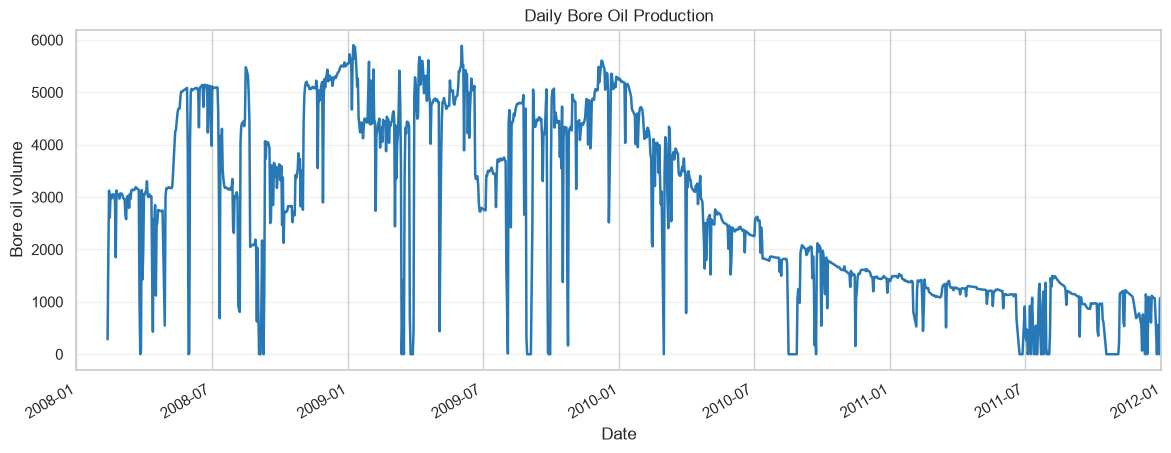

In [21]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].plot(xlim=["2008-01-01", "2012"], figsize=(14, 5), title="Daily Bore Oil Production", color="#2878B5", linewidth=1.8)
ax.set(xlabel="Date", ylabel="Bore oil volume")
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/02_daily_bore_oil_production.png", dpi=300, bbox_inches="tight")


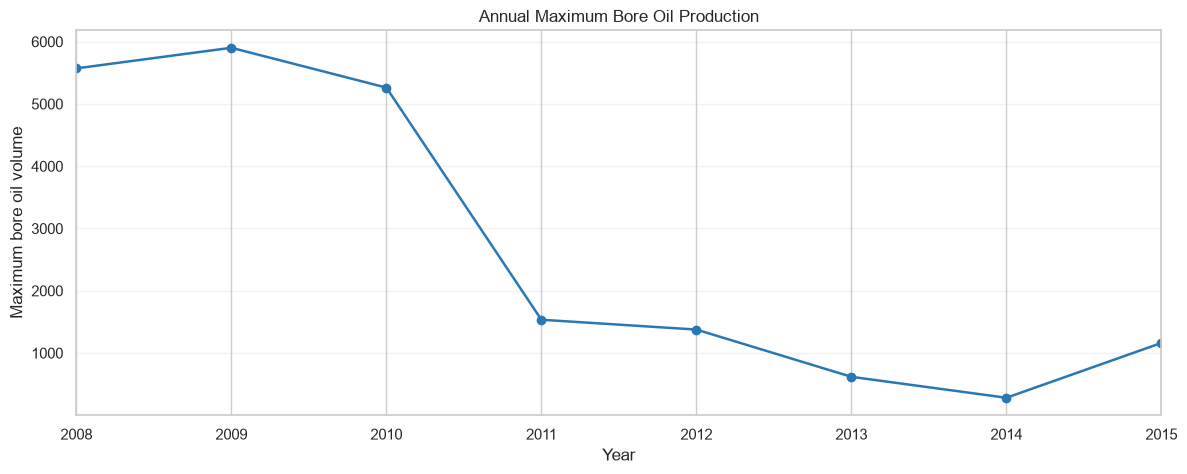

In [22]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].resample(rule="YE").max().plot(figsize=(14, 5), title="Annual Maximum Bore Oil Production", color="#2878B5", linewidth=1.8, marker="o")
ax.set(xlabel="Year", ylabel="Maximum bore oil volume")
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/03_annual_maximum_bore_oil_production.png", dpi=300, bbox_inches="tight")


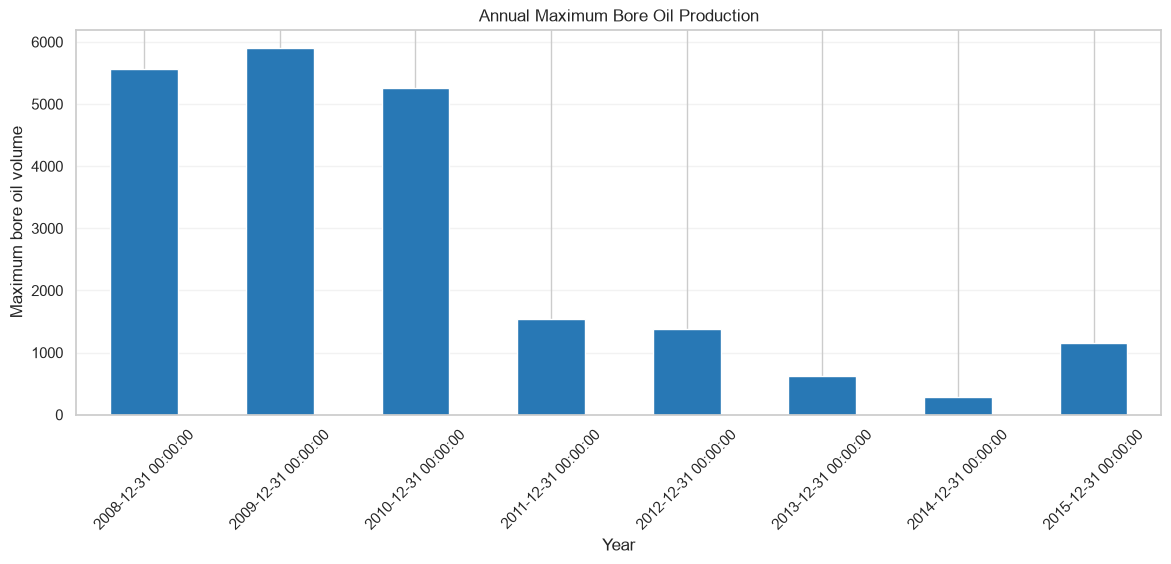

In [23]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].resample(rule="YE").max().plot(kind="bar", figsize=(14, 5), title="Annual Maximum Bore Oil Production", color="#2878B5", edgecolor="white")
ax.set(xlabel="Year", ylabel="Maximum bore oil volume")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/04_annual_maximum_bore_oil_production_bar.png", dpi=300, bbox_inches="tight")


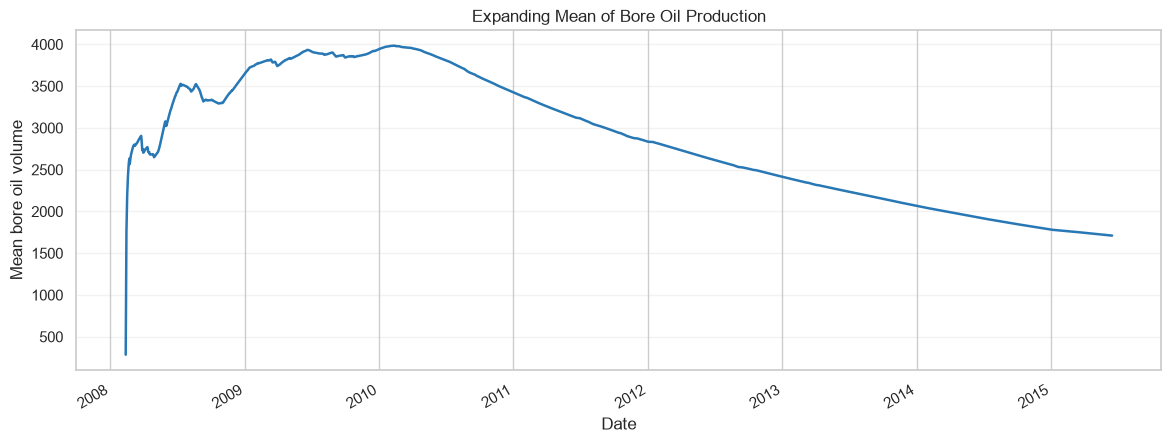

In [24]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].expanding().mean().plot(xlabel="Date", ylabel="Mean bore oil volume", figsize=(14, 5), title="Expanding Mean of Bore Oil Production", color="#2878B5", linewidth=1.8)
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/06_expanding_mean_bore_oil_production.png", dpi=300, bbox_inches="tight")


## Time-Series Diagnostics

Use differencing, the ADF test, decomposition, and autocorrelation plots to inspect stationarity.

### Stationarity Diagnostics

Difference the training target; retain the raw series for forecasting.

In [ ]:
diagnostic_df = train_df[["BORE_OIL_VOL"]].copy()
diagnostic_df["Differenced_BORE_OIL_VOL"] = diagnostic_df["BORE_OIL_VOL"].diff()
diagnostic_df.dropna(subset=["Differenced_BORE_OIL_VOL"], inplace=True)

In [ ]:
print(diagnostic_df[["BORE_OIL_VOL", "Differenced_BORE_OIL_VOL"]].head())

In [ ]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = diagnostic_df["Differenced_BORE_OIL_VOL"].plot(figsize=(14, 5), title="Differenced Bore Oil Production", color="#2878B5", linewidth=1.5)
ax.set(xlabel="Date", ylabel="Change in bore oil volume")
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/07_differenced_bore_oil_production.png", dpi=300, bbox_inches="tight")

In [ ]:
diagnostic_result = sm.tsa.stattools.adfuller(diagnostic_df['Differenced_BORE_OIL_VOL'])
print('ADF Statistic:', diagnostic_result[0])
print('p-value:', diagnostic_result[1])

if diagnostic_result[1] < 0.05:
    print("Data is stationary")
else:
    print("Data is non-stationary")

In [ ]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
from statsmodels.tsa.seasonal import seasonal_decompose
diagnostic_result = seasonal_decompose(diagnostic_df["Differenced_BORE_OIL_VOL"], model="additive", period=12)
fig = diagnostic_result.plot()
fig.set_size_inches(14, 9)
for ax, label in zip(fig.axes, ["Observed change", "Trend", "Seasonal component", "Residual"]):
    ax.set_xlabel("Date")
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/08_seasonal_decomposition.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
differenced_oil_volume = diagnostic_df["Differenced_BORE_OIL_VOL"].dropna()
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
plot_acf(differenced_oil_volume, lags=100, ax=axes[0], title="Autocorrelation of Differenced Bore Oil Production")
plot_pacf(differenced_oil_volume, lags=100, ax=axes[1], method="ywadjusted", title="Partial Autocorrelation of Differenced Bore Oil Production")
axes[0].set(xlabel="Lag (observations)", ylabel="Autocorrelation")
axes[1].set(xlabel="Lag (observations)", ylabel="Partial autocorrelation")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/09_acf_pacf_differenced_production.png", dpi=300, bbox_inches="tight")
plt.show()

## Forecasting Models

Compare ARIMA, XGBoost, and LSTM.

### ARIMA

Fit ARIMA(3, 1, 2) on training data and forecast 30 days.

In [ ]:
training_oil_volume = train_df['BORE_OIL_VOL'].reset_index(drop=True)
model = sm.tsa.ARIMA(training_oil_volume, order=(3, 1, 2))
arima_model_fit = model.fit()

arima_forecast = arima_model_fit.forecast(steps=30)

arima_forecast.index = pd.date_range(
    start=train_df.index[-1] + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

In [ ]:
arima_model_fit.summary()

In [ ]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_df.index, test_df["BORE_OIL_VOL"], label="Actual", color="#2878B5", linewidth=1.8)
ax.plot(arima_forecast.index, arima_forecast, label="ARIMA forecast", color="#E07A2D", linewidth=1.8, linestyle="--")
ax.set(title="ARIMA Forecast vs. Actual Bore Oil Production", xlabel="Date", ylabel="Bore oil volume")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/10_arima_forecast_vs_actual.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:

residuals = pd.Series(test_df["BORE_OIL_VOL"] - arima_forecast, index=test_df.index, name="Residuals")


In [ ]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = arima_model_fit.resid.plot(kind="kde", figsize=(12, 5), title="ARIMA Model Residual Distribution", color="#2878B5", linewidth=1.8)
ax.set(xlabel="Residual", ylabel="Probability density")
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/11_arima_residual_distribution.png", dpi=300, bbox_inches="tight")


### XGBoost Baseline and Optuna-Tuned Model

The fixed-parameter model is a baseline. The Optuna-selected model is the final XGBoost model used by the source pipeline.

### Build Lag Features

Create `lag_1` through `lag_30` and define chronological train, validation, and test windows.

In [ ]:
def lag_features(df, n=30):
    df= df.copy()
    lag_feature_names=[]
    for i in range(1,n+1):
        df[f"lag_{i}"] = df["BORE_OIL_VOL"].shift(i)
        lag_feature_names.append(f"lag_{i}")

    return df, lag_feature_names

In [ ]:
train_df, lag_feature_names= lag_features(train_df, n=30)
test_df, _= lag_features(test_df, n=30)
train_df.dropna(inplace=True)

#### Train and Validation Windows

Train ends 2014-07-15; validation runs 2014-08-16 to 2015-06-16.

In [ ]:
x_train = train_df.loc[: "2014-07-15", lag_feature_names]
y_train = train_df.loc[: "2014-07-15", "BORE_OIL_VOL"]

x_val = train_df.loc["2014-08-16":"2015-06-16", lag_feature_names]
y_val = train_df.loc["2014-08-16":"2015-06-16", "BORE_OIL_VOL"]

In [ ]:
x_train.loc[:,lag_feature_names].tail(30)

In [ ]:
x_val.loc[:,lag_feature_names].head(30)

#### Test Evaluation

Test lags use earlier observed test values, so scores measure rolling one-step-ahead forecasts.

In [ ]:
test_df.dropna(inplace=True)

In [ ]:
x_test= test_df[lag_feature_names]
y_test= test_df["BORE_OIL_VOL"]

In [ ]:
xgboost_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    objective='reg:squarederror',
    n_jobs=-1,
    random_state=42,
    early_stopping_rounds=50
)

In [ ]:
xgboost_model.fit(
    x_train,
    y_train,
    eval_set=[
        (x_train, y_train), 
        (x_val, y_val)
        ],
    verbose=100  
)

In [ ]:
xgboost_predictions = xgboost_model.predict(x_test)

In [ ]:
rmse = np.sqrt(mean_squared_error(y_test, xgboost_predictions))
r2 = r2_score(y_test, xgboost_predictions)
print(f"Root Mean Squared Error: {rmse}")
print(f"R-squared: {r2}")

#### Optuna Hyperparameter Search

Select parameters by validation RMSE.

In [ ]:
def objective(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 300, 1500
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.1, log=True
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 2, 10
        ),

        "min_child_weight": trial.suggest_int(
            "min_child_weight", 1, 10
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.6, 1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),

        "gamma": trial.suggest_float(
            "gamma", 0, 5
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-8, 10.0, log=True
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-8, 10.0, log=True
        ),

        "objective": "reg:squarederror",

        "n_jobs": -1,

        "random_state": 42,

        "early_stopping_rounds": 50
    }

    model = XGBRegressor(**params)

    model.fit(
        x_train,
        y_train,
        eval_set=[(x_val, y_val)],
        verbose=False
    )

    val_pred = model.predict(x_val)

    rmse = np.sqrt(
        mean_squared_error(y_val, val_pred)
    )

    return rmse

In [ ]:
study = optuna.create_study(
    direction="minimize",
    study_name="xgb_production_forecasting"
)

study.optimize(
    objective,
    n_trials=100
)

In [ ]:
best_params = study.best_params.copy()

best_params.update({
    "objective": "reg:squarederror",
    "n_jobs": -1,
    "random_state": 42,
    "early_stopping_rounds": 50
})

final_model = XGBRegressor(**best_params)

final_model.fit(
    x_train,
    y_train,
    eval_set=[(x_val, y_val)],
    verbose=False
)

In [ ]:
test_pred = final_model.predict(x_test)

test_rmse = np.sqrt(
    mean_squared_error(y_test, test_pred)
)

test_r2 = r2_score(y_test, test_pred)
print(f"Test RMSE: {test_rmse:.2f}")
print(f"Test R^2: {test_r2:.2f}")

In [ ]:
print("Best validation RMSE:", study.best_value)
print("Best parameters:")
print(study.best_params)

print("Train shape:", x_train.shape)
print("Validation shape:", x_val.shape)
print("Test shape:", x_test.shape)

In [ ]:
joblib.dump(final_model, "models/xgb_production_forecasting_model.pkl")

In [ ]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_df.index, test_df["BORE_OIL_VOL"], label="Actual", color="#2878B5", linewidth=1.8)
ax.plot(test_df.index, test_pred, label="XGBoost forecast", color="#E07A2D", linewidth=1.8, linestyle="--")
ax.set(title="XGBoost Forecast vs. Actual Bore Oil Production", xlabel="Date", ylabel="Bore oil volume")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/12_xgboost_forecast.png", dpi=300, bbox_inches="tight")
plt.show()

### LSTM with the Same Lag Windows

Scale using training data, stop training based on validation loss, and score predictions in original units.

### LSTM Training and Evaluation

Scale lag features, train with validation-based early stopping, then plot test predictions.

In [ ]:
from sklearn.preprocessing import StandardScaler

feature_scaler = StandardScaler()
target_scaler = StandardScaler()

x_train_scaled = feature_scaler.fit_transform(x_train)
x_val_scaled = feature_scaler.transform(x_val)
x_test_scaled = feature_scaler.transform(x_test)

y_train_scaled = target_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1))
y_val_scaled = target_scaler.transform(y_val.to_numpy().reshape(-1, 1))

x_train_lstm = x_train_scaled.reshape(x_train_scaled.shape[0], len(lag_feature_names), 1)
x_val_lstm = x_val_scaled.reshape(x_val_scaled.shape[0], len(lag_feature_names), 1)
x_test_lstm = x_test_scaled.reshape(x_test_scaled.shape[0], len(lag_feature_names), 1)


In [ ]:
from keras.callbacks import EarlyStopping

lstm_model = Sequential()
lstm_model.add(LSTM(64, input_shape=(len(lag_feature_names), 1)))
lstm_model.add(Dense(1))

lstm_model.compile(optimizer="adam", loss="mean_squared_error")


In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=45,
    restore_best_weights=True
)

history = lstm_model.fit(
    x_train_lstm,
    y_train_scaled,
    validation_data=(x_val_lstm, y_val_scaled),
    epochs=100,
    batch_size=16,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=10
)


In [ ]:
scaled_lstm_predictions = lstm_model.predict(x_test_lstm, verbose=0)
lstm_predictions = target_scaler.inverse_transform(scaled_lstm_predictions).ravel()

lstm_rmse = np.sqrt(mean_squared_error(y_test, lstm_predictions))
lstm_r2 = r2_score(y_test, lstm_predictions)

print(f"Root Mean Squared Error: {lstm_rmse}")
print(f"R-squared: {lstm_r2}")


In [ ]:
joblib.dump(
    {
        "model": lstm_model,
        "x_scaler": feature_scaler,
        "y_scaler": target_scaler,
        "lags": lag_feature_names,
    },
    "models/lstm_production_forecasting_model.pkl",
)

In [ ]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_test.index, y_test, label="Actual", color="#2878B5", linewidth=1.8)
ax.plot(y_test.index, lstm_predictions, label="LSTM forecast", color="#E07A2D", linewidth=1.8, linestyle="--")
ax.set(title="LSTM Forecast vs. Actual Bore Oil Production", xlabel="Date", ylabel="Bore oil volume")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/13_lstm_forecast_vs_actual.png", dpi=300, bbox_inches="tight")
plt.show()
